# Homework: Propositional Logic

Given a knowledge base with 17 definite clauses as below.

$
\begin{aligned}
1.\;& A \land B \Rightarrow C \\
2.\;& A \Rightarrow D \\
3.\;& C \land D \Rightarrow E \\
4.\;& E \Rightarrow F \\
5.\;& B \Rightarrow G \\
6.\;& F \land G \Rightarrow H \\
7.\;& H \Rightarrow I \\
8.\;& I \land D \Rightarrow J \\
9.\;& J \Rightarrow K \\
10.\;& K \land A \Rightarrow L \\
11.\;& L \Rightarrow M \\
12.\;& M \land G \Rightarrow N \\
13.\;& N \Rightarrow O \\
14.\;& O \land C \Rightarrow P \\
15.\;& P \Rightarrow Q \\
16.\;& A \\
17.\;& B
\end{aligned}
$

## TODO 1:

Use the **graphviz** library to draw a graph illustrating the knowledge base abov, for example,

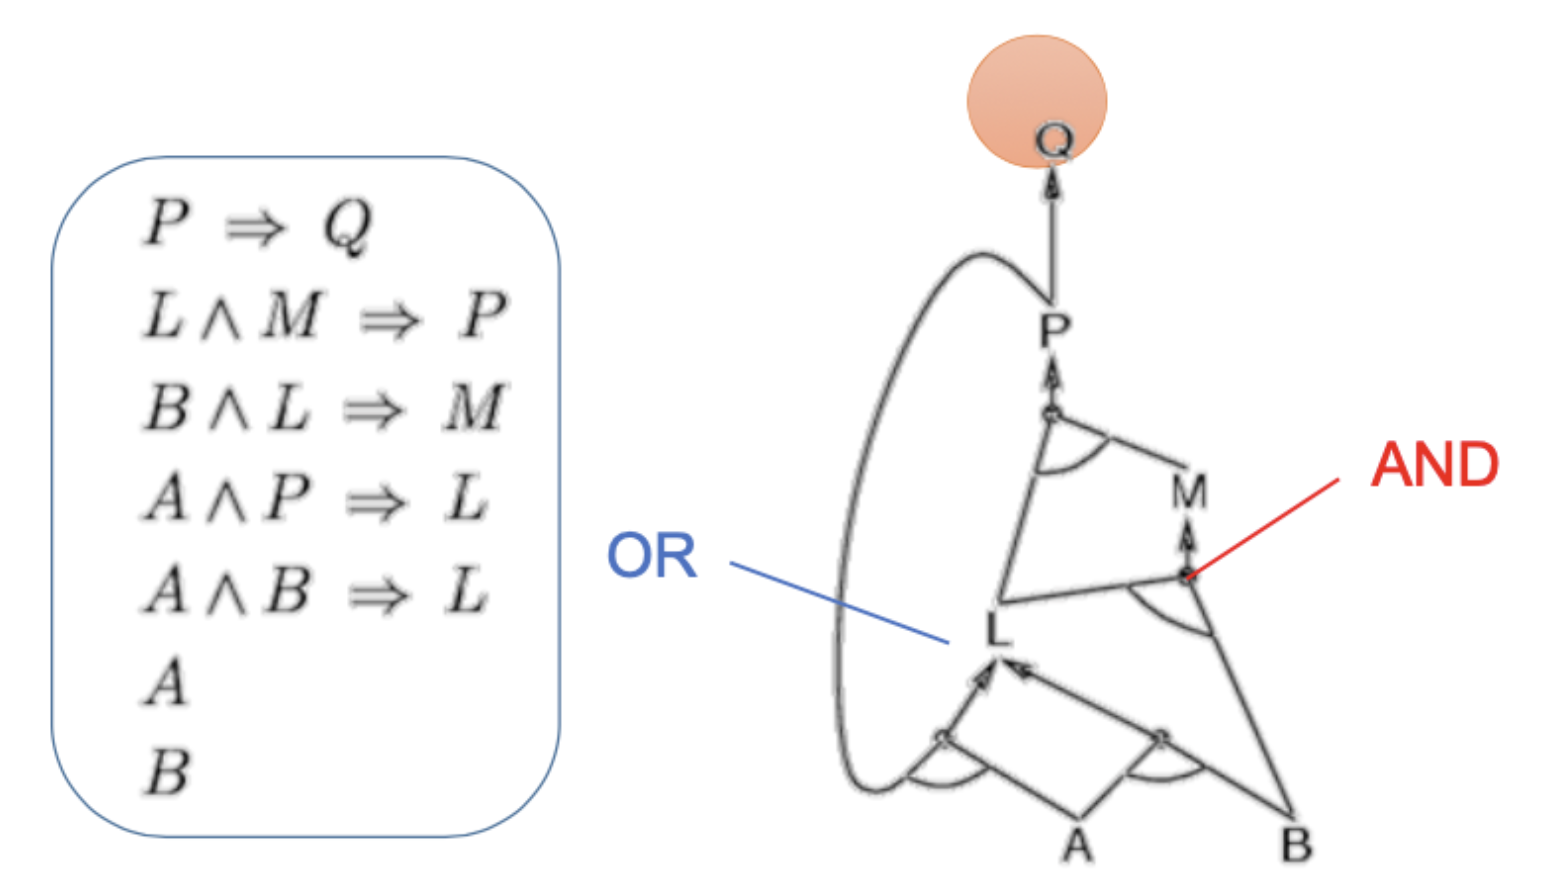

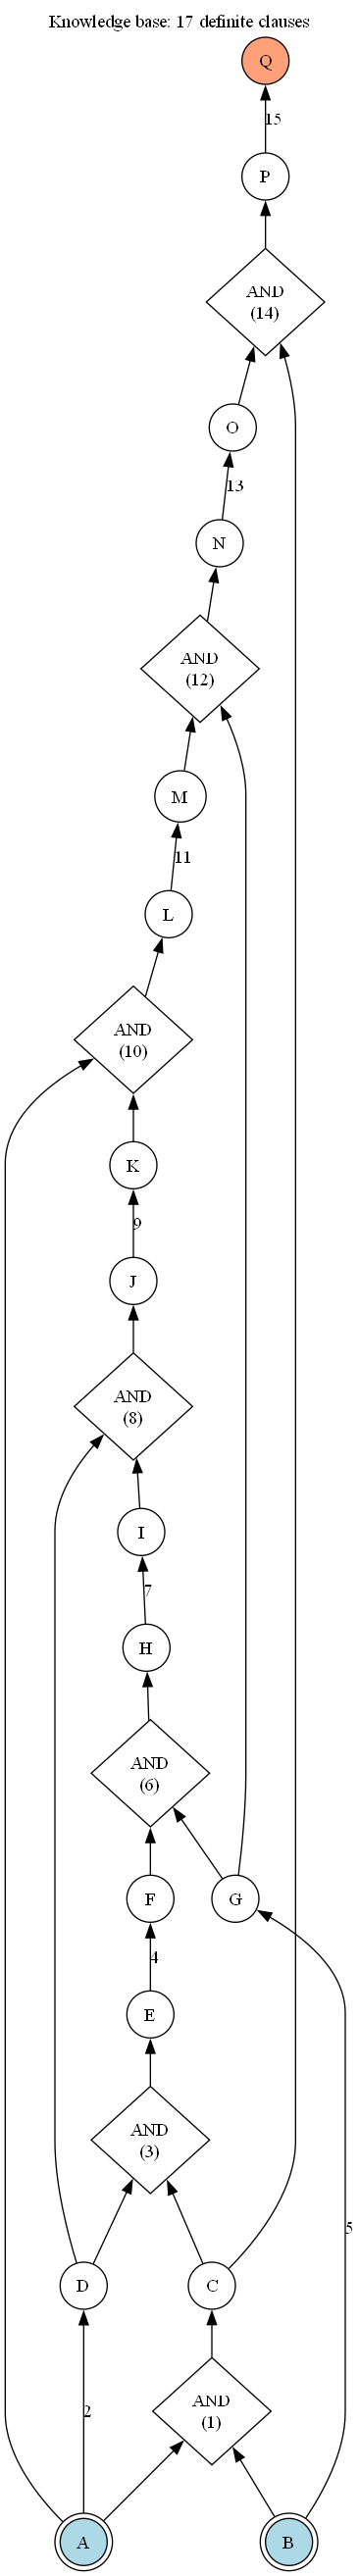

In [1]:
from graphviz import Digraph
from IPython.display import Image, display

# Each clause is (premises, conclusion); an empty premise tuple is a fact.
KB = [
    (('A', 'B'), 'C'),
    (('A',), 'D'),
    (('C', 'D'), 'E'),
    (('E',), 'F'),
    (('B',), 'G'),
    (('F', 'G'), 'H'),
    (('H',), 'I'),
    (('I', 'D'), 'J'),
    (('J',), 'K'),
    (('K', 'A'), 'L'),
    (('L',), 'M'),
    (('M', 'G'), 'N'),
    (('N',), 'O'),
    (('O', 'C'), 'P'),
    (('P',), 'Q'),
    ((), 'A'),
    ((), 'B'),
]

graph = Digraph('KnowledgeBase', format='png')
graph.attr(rankdir='BT', label='Knowledge base: 17 definite clauses', labelloc='t')
for symbol in sorted({s for premises, conclusion in KB for s in (*premises, conclusion)}):
    attributes = {'shape': 'circle'}
    if symbol in ('A', 'B'):
        attributes.update(shape='doublecircle', style='filled', fillcolor='lightblue')
    elif symbol == 'Q':
        attributes.update(style='filled', fillcolor='lightsalmon')
    graph.node(symbol, **attributes)

for number, (premises, conclusion) in enumerate(KB, start=1):
    if len(premises) > 1:
        # A shared AND node requires every premise, rather than either premise.
        rule = f'rule_{number}'
        graph.node(rule, label=f'AND\n({number})', shape='diamond')
        for premise in premises:
            graph.edge(premise, rule)
        graph.edge(rule, conclusion)
    elif premises:
        graph.edge(premises[0], conclusion, label=str(number))

display(Image(graph.pipe()))


## TODO 2:

Implement the Forward Chaining algorithm and print propositions down according to the inferred orde, in which the query proposition is **Q**.

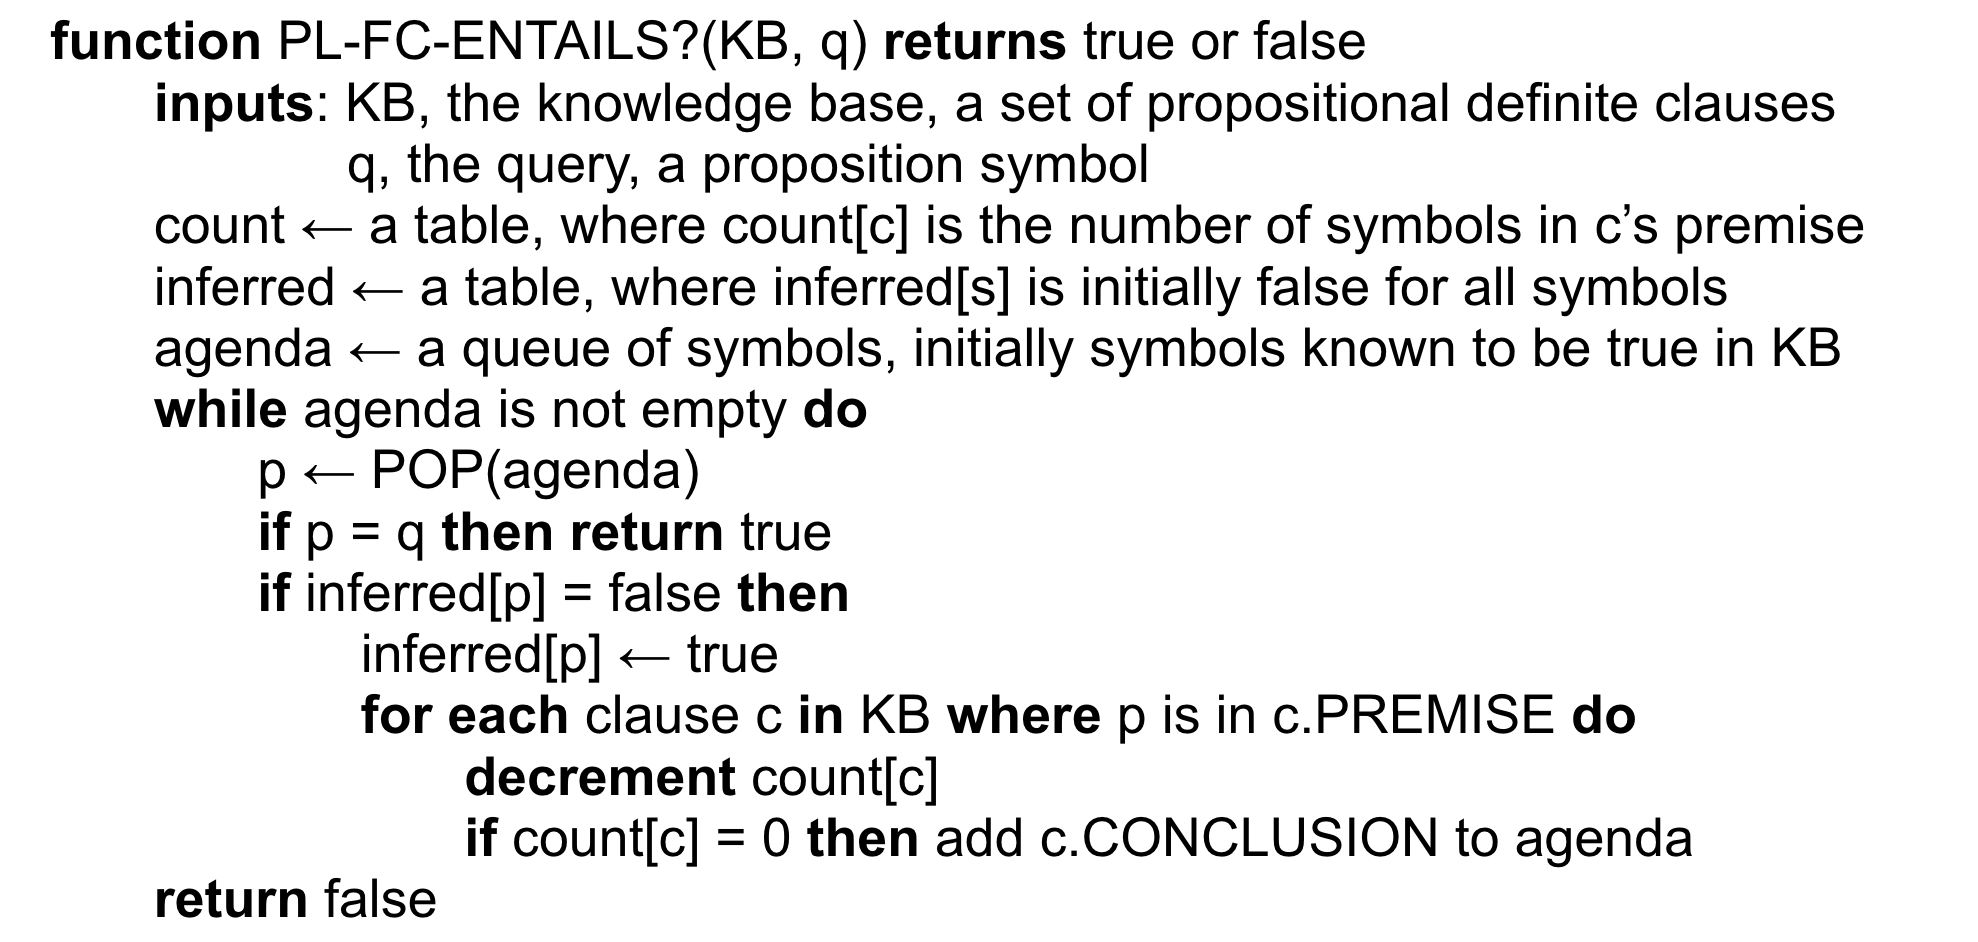

In [2]:
from collections import deque


def PL_FC_ENTAILS(KB, q='Q'):
    """Print FIFO inference order and return whether definite clauses entail q."""
    count = [len(set(premises)) for premises, _ in KB]
    inferred = set()
    agenda = deque(conclusion for premises, conclusion in KB if not premises)

    while agenda:
        p = agenda.popleft()
        if p in inferred:
            continue
        print(p)
        if p == q:
            return True
        inferred.add(p)
        for index, (premises, conclusion) in enumerate(KB):
            if p in premises:
                count[index] -= 1
                if count[index] == 0:
                    agenda.append(conclusion)
    return False


## TODO 3:

Execute the PL_FC_ENTAILS() function to show propositions in the inferred order. You need to prepare the KB in advance.

In [3]:
# KB was prepared in TODO 1, using all 17 clauses in the given order.
entails_q = PL_FC_ENTAILS(KB, q='Q')
print('Entails Q:', entails_q)


A
B
D
C
G
E
F
H
I
J
K
L
M
N
O
P
Q
Entails Q: True


# Submission

*   Students download the notebook after completion
*   Rename the notebook in which inserting your student ID at the beginning. \
For example, **123456-lec09-PropositionalLogic-HW.ipynb**
*   Finally, submit the file